In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score, classification_report

In [10]:
df = pd.read_csv('water_potability.csv')# Load the data base

In [11]:
df.shape#Check rows and columns

(3276, 10)

In [12]:
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [13]:
df.duplicated().sum()

0

In [14]:
df.head()#See how our data looks

<bound method NDFrame.head of             ph    Hardness        Solids  Chloramines     Sulfate   
0          NaN  204.890455  20791.318981     7.300212  368.516441  \
1     3.716080  129.422921  18630.057858     6.635246         NaN   
2     8.099124  224.236259  19909.541732     9.275884         NaN   
3     8.316766  214.373394  22018.417441     8.059332  356.886136   
4     9.092223  181.101509  17978.986339     6.546600  310.135738   
...        ...         ...           ...          ...         ...   
3271  4.668102  193.681735  47580.991603     7.166639  359.948574   
3272  7.808856  193.553212  17329.802160     8.061362         NaN   
3273  9.419510  175.762646  33155.578218     7.350233         NaN   
3274  5.126763  230.603758  11983.869376     6.303357         NaN   
3275  7.874671  195.102299  17404.177061     7.509306         NaN   

      Conductivity  Organic_carbon  Trihalomethanes  Turbidity  Potability  
0       564.308654       10.379783        86.990970   2.963135  

In [15]:
print(df.isnull().sum())#How many Null values we have

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64


In [16]:
imputer = KNNImputer(n_neighbors=5)
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)#Getting nulls out using the imputation of KNN 


In [17]:
X = df_imputed.drop('Potability', axis=1)
y = df_imputed['Potability'].round().astype(int)

In [18]:
print(df_imputed.isnull().sum())#See how many null figures we have now

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64


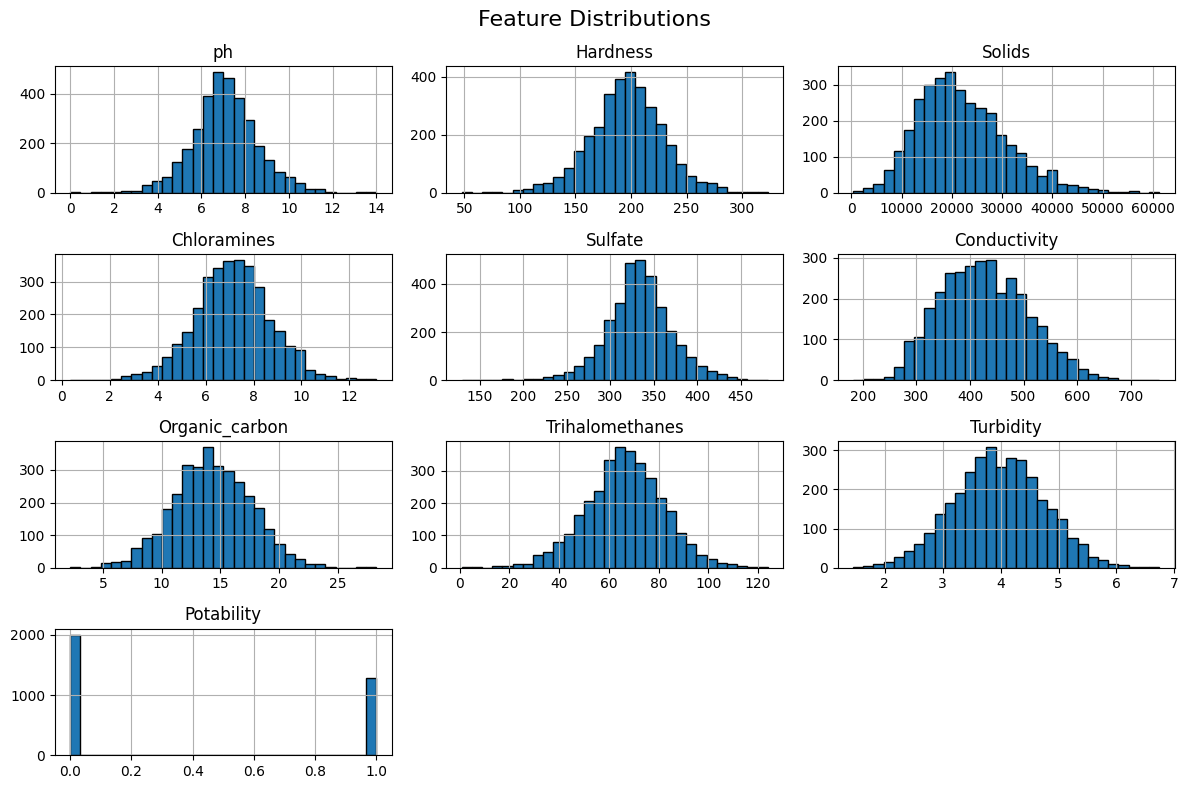

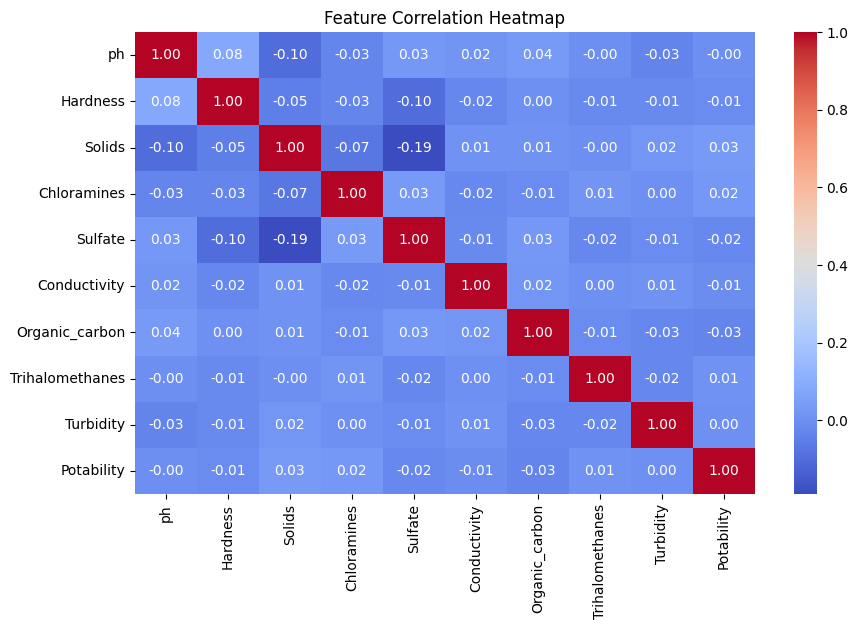

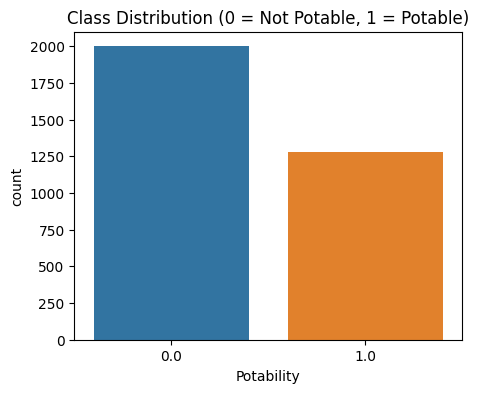

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# ── Distribution of each feature ─────────────────────────
df_imputed.hist(figsize=(12, 8), bins=30, edgecolor='black')
plt.suptitle('Feature Distributions', fontsize=16)
plt.tight_layout()
plt.show()

# ── Correlation heatmap ───────────────────────────────────
plt.figure(figsize=(10, 6))
sns.heatmap(df_imputed.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

# ── Class distribution ────────────────────────────────────
plt.figure(figsize=(5, 4))
sns.countplot(x='Potability', data=df_imputed)
plt.title('Class Distribution (0 = Not Potable, 1 = Potable)')
plt.show()

In [20]:
X = df_imputed.drop('Potability', axis=1)
y = df_imputed['Potability'].round().astype(int)#Splitting the feature and the targets

In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)#Scaling the data

In [22]:
from sklearn.model_selection import train_test_split#Train Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

In [23]:
lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

print("Baseline Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Baseline Logistic Regression
Accuracy: 0.5
              precision    recall  f1-score   support

           0       0.63      0.51      0.56       412
           1       0.37      0.49      0.42       244

    accuracy                           0.50       656
   macro avg       0.50      0.50      0.49       656
weighted avg       0.53      0.50      0.51       656



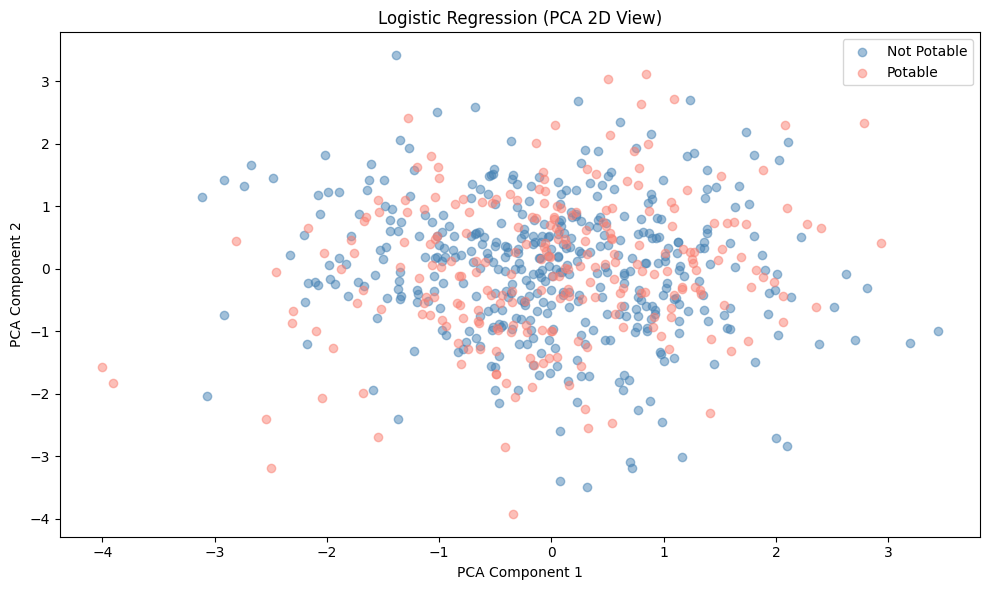

In [24]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reduce to 2D using PCA
pca = PCA(n_components=2)
X_test_2d = pca.fit_transform(X_test)

# Plot
plt.figure(figsize=(10, 6))

plt.scatter(X_test_2d[y_test == 0, 0], X_test_2d[y_test == 0, 1],
            c='steelblue', label='Not Potable', alpha=0.5)
plt.scatter(X_test_2d[y_test == 1, 0], X_test_2d[y_test == 1, 1],
            c='salmon', label='Potable', alpha=0.5)

plt.title('Logistic Regression (PCA 2D View)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C':        [0.01, 0.1, 1, 10, 100],
    'penalty':  ['l1', 'l2'],
    'solver':   ['liblinear', 'saga']
}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight='balanced'), 
    param_grid, cv=5, scoring='f1'  # change scoring to f1 instead of accuracy
)
grid.fit(X_train, y_train)

print("Best Params:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

y_pred_tuned = grid.best_estimator_.predict(X_test)
print("\nTest Accuracy:", accuracy_score(y_test, y_pred_tuned))
print(classification_report(y_test, y_pred_tuned, zero_division=0))

Best Params: {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}
Best CV Score: 0.43773250505939815

Test Accuracy: 0.5015243902439024
              precision    recall  f1-score   support

           0       0.63      0.51      0.56       412
           1       0.37      0.49      0.42       244

    accuracy                           0.50       656
   macro avg       0.50      0.50      0.49       656
weighted avg       0.53      0.50      0.51       656



In [26]:
# See correlation of each feature with Potability
correlations = df_imputed.corr()['Potability'].abs().sort_values()
print("Feature correlations with Potability:")
print(correlations)

Feature correlations with Potability:
Turbidity          0.001581
ph                 0.002920
Trihalomethanes    0.006918
Conductivity       0.008128
Hardness           0.013837
Sulfate            0.022108
Chloramines        0.023779
Organic_carbon     0.030001
Solids             0.033743
Potability         1.000000
Name: Potability, dtype: float64


In [27]:
# Drop 3 weakest features
weak_features = ['Turbidity', 'ph', 'Trihalomethanes']
X_reduced = df_imputed.drop(columns=['Potability'] + weak_features)

print("Remaining features:", X_reduced.columns.tolist())

# Scale
X_reduced_scaled = scaler.fit_transform(X_reduced)

# Train/test split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reduced_scaled, y, test_size=0.2, random_state=42
)

# Train model with best params from GridSearchCV
lr_reduced = LogisticRegression(max_iter=1000, class_weight='balanced', **grid.best_params_)
lr_reduced.fit(X_train_r, y_train_r)

y_pred_r = lr_reduced.predict(X_test_r)

print("\nAfter Feature Removal")
print("Accuracy:", accuracy_score(y_test_r, y_pred_r))
print(classification_report(y_test_r, y_pred_r, zero_division=0))

Remaining features: ['Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon']

=== After Feature Removal ===
Accuracy: 0.5213414634146342
              precision    recall  f1-score   support

           0       0.64      0.54      0.59       412
           1       0.39      0.49      0.43       244

    accuracy                           0.52       656
   macro avg       0.51      0.51      0.51       656
weighted avg       0.55      0.52      0.53       656



In [28]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42, class_weight='balanced')
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("Baseline Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt, zero_division=0))

=== Baseline Decision Tree ===
Accuracy: 0.600609756097561
              precision    recall  f1-score   support

           0       0.68      0.68      0.68       412
           1       0.46      0.46      0.46       244

    accuracy                           0.60       656
   macro avg       0.57      0.57      0.57       656
weighted avg       0.60      0.60      0.60       656



In [29]:
from sklearn.model_selection import GridSearchCV

param_grid_dt = {
    'max_depth':        [3, 5, 10, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf':  [1, 2, 4],
    'criterion':         ['gini', 'entropy']
}

grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    param_grid_dt, cv=5, scoring='f1'
)
grid_dt.fit(X_train, y_train)

print("Best Params:", grid_dt.best_params_)
print("Best CV Score:", grid_dt.best_score_)

y_pred_dt_tuned = grid_dt.best_estimator_.predict(X_test)

print("\nAfter GridSearchCV ")
print("Accuracy:", accuracy_score(y_test, y_pred_dt_tuned))
print(classification_report(y_test, y_pred_dt_tuned, zero_division=0))

Best Params: {'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 4, 'min_samples_split': 10}
Best CV Score: 0.5072319787355183

=== After GridSearchCV ===
Accuracy: 0.5884146341463414
              precision    recall  f1-score   support

           0       0.68      0.66      0.67       412
           1       0.45      0.46      0.46       244

    accuracy                           0.59       656
   macro avg       0.56      0.56      0.56       656
weighted avg       0.59      0.59      0.59       656



In [30]:
# Use same correlations from before
print("Feature correlations with Potability:")
print(correlations)

# Drop 3 weakest features
weak_features = ['Turbidity', 'ph', 'Trihalomethanes']
X_reduced_dt = df_imputed.drop(columns=['Potability'] + weak_features)

print("\nRemaining features:", X_reduced_dt.columns.tolist())

# Scale
X_reduced_dt_scaled = scaler.fit_transform(X_reduced_dt)

# Train/test split
X_train_dt_r, X_test_dt_r, y_train_dt_r, y_test_dt_r = train_test_split(
    X_reduced_dt_scaled, y, test_size=0.2, random_state=42
)

# Train with best params from GridSearchCV
dt_reduced = DecisionTreeClassifier(
    random_state=42, 
    class_weight='balanced', 
    **grid_dt.best_params_
)
dt_reduced.fit(X_train_dt_r, y_train_dt_r)

y_pred_dt_r = dt_reduced.predict(X_test_dt_r)

print("\n=== Decision Tree After Feature Removal ===")
print("Accuracy:", accuracy_score(y_test_dt_r, y_pred_dt_r))
print(classification_report(y_test_dt_r, y_pred_dt_r, zero_division=0))

Feature correlations with Potability:
Turbidity          0.001581
ph                 0.002920
Trihalomethanes    0.006918
Conductivity       0.008128
Hardness           0.013837
Sulfate            0.022108
Chloramines        0.023779
Organic_carbon     0.030001
Solids             0.033743
Potability         1.000000
Name: Potability, dtype: float64

Remaining features: ['Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon']

=== Decision Tree After Feature Removal ===
Accuracy: 0.5045731707317073
              precision    recall  f1-score   support

           0       0.62      0.54      0.58       412
           1       0.36      0.45      0.40       244

    accuracy                           0.50       656
   macro avg       0.49      0.49      0.49       656
weighted avg       0.53      0.50      0.51       656

